# Thực hành: Các phương pháp Ensemble

**Môn:** Nhận dạng mẫu

**Mục tiêu:** dùng sklearn cài đặt Bagging, Random Forest, AdaBoost, Gradient Boosting, XGBoost và so sánh với các mô hình đơn.

| Phần | Nội dung | Dữ liệu |
|---|---|---|
| **A. Ví dụ mẫu** (đọc và chạy) | A1 EDA, A2 cách dùng từng thuật toán, A3 bảng benchmark | Iris, Two Moons |
| **B. Bài tập** (sinh viên làm) | Lặp lại quy trình A1 đến A3 | Optdigits (UCI) |

**Yêu cầu môi trường:** Python ≥ 3.9, scikit-learn ≥ 1.2, xgboost, ucimlrepo.

In [1]:
!pip install -q ucimlrepo xgboost


[notice] A new release of pip is available: 26.2.1 -> 26.2.2
[notice] To update, run: python.exe -m pip install --upgrade pip


In [2]:
import time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from ucimlrepo import fetch_ucirepo

from sklearn.base import clone
from sklearn.datasets import make_moons
from sklearn.model_selection import train_test_split, cross_val_score
from sklearn.preprocessing import LabelEncoder, StandardScaler
from sklearn.pipeline import make_pipeline
from sklearn.metrics import accuracy_score, f1_score, confusion_matrix, ConfusionMatrixDisplay

# Mô hình đơn
from sklearn.tree import DecisionTreeClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.neighbors import KNeighborsClassifier
from sklearn.svm import SVC
# Mô hình ensemble
from sklearn.ensemble import (BaggingClassifier, RandomForestClassifier,
                              AdaBoostClassifier, GradientBoostingClassifier)
from xgboost import XGBClassifier

SEED = 42
COLORS = ["#2a78d6", "#eb6834", "#1baf7a", "#eda100", "#e87ba4", "#008300"]
plt.rcParams.update({"axes.prop_cycle": plt.cycler(color=COLORS),
                     "axes.spines.top": False, "axes.spines.right": False,
                     "axes.grid": True, "grid.alpha": 0.25, "figure.dpi": 100})

---
# Phần A. Ví dụ mẫu

## A1. Dữ liệu và EDA

### Iris (UCI id 53)
150 mẫu hoa diên vĩ (Iris), **4 đặc trưng** (cm): chiều dài và chiều rộng của đài hoa (sepal), cánh hoa (petal). **3 lớp** (setosa, versicolor, virginica), mỗi lớp 50 mẫu. Đây là bài toán phân loại đa lớp nhỏ, dễ quan sát.

In [25]:
iris.data

{'ids': None,
 'features':      sepal length  sepal width  petal length  petal width
 0             5.1          3.5           1.4          0.2
 1             4.9          3.0           1.4          0.2
 2             4.7          3.2           1.3          0.2
 3             4.6          3.1           1.5          0.2
 4             5.0          3.6           1.4          0.2
 ..            ...          ...           ...          ...
 145           6.7          3.0           5.2          2.3
 146           6.3          2.5           5.0          1.9
 147           6.5          3.0           5.2          2.0
 148           6.2          3.4           5.4          2.3
 149           5.9          3.0           5.1          1.8
 
 [150 rows x 4 columns],
 'targets':               class
 0       Iris-setosa
 1       Iris-setosa
 2       Iris-setosa
 3       Iris-setosa
 4       Iris-setosa
 ..              ...
 145  Iris-virginica
 146  Iris-virginica
 147  Iris-virginica
 148  Iris-virgini

In [3]:
iris = fetch_ucirepo(id=53)
X_iris = iris.data.features
y_names = iris.data.targets.iloc[:, 0]
le = LabelEncoder()
y_iris = le.fit_transform(y_names)          # nhãn chữ -> 0, 1, 2 (XGBoost bắt buộc)

print("Kích thước:", X_iris.shape, "| Giá trị thiếu:", X_iris.isna().sum().sum())
print(y_names.value_counts(), "\n")
X_iris.describe().round(2)

Kích thước: (150, 4) | Giá trị thiếu: 0
class
Iris-setosa        50
Iris-versicolor    50
Iris-virginica     50
Name: count, dtype: int64 



,sepal length,sepal width,petal length,petal width
count,150.00,150.00,150.00,150.00
mean,5.84,3.05,3.76,1.20
std,0.83,0.43,1.76,0.76
min,4.30,2.00,1.00,0.10
25%,5.10,2.80,1.60,0.30
50%,5.80,3.00,4.35,1.30
75%,6.40,3.30,5.10,1.80
max,7.90,4.40,6.90,2.50


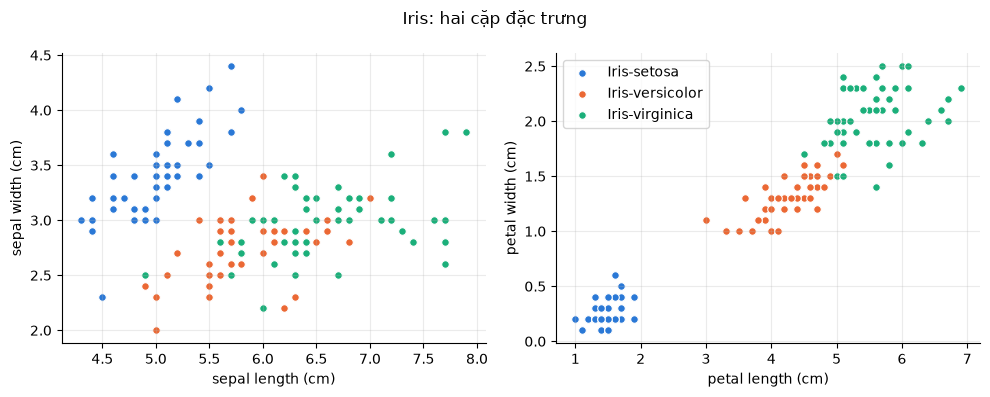

In [4]:
fig, axes = plt.subplots(1, 2, figsize=(10, 4))
pairs = [("sepal length", "sepal width"), ("petal length", "petal width")]
for ax, (fx, fy) in zip(axes, pairs):
    for k, name in enumerate(le.classes_):
        m = y_iris == k
        ax.scatter(X_iris.loc[m, fx], X_iris.loc[m, fy], s=30, label=name,
                   edgecolor="white", linewidth=0.8)
    ax.set_xlabel(fx + " (cm)"); ax.set_ylabel(fy + " (cm)")
axes[1].legend(loc="upper left")
fig.suptitle("Iris: hai cặp đặc trưng")
plt.tight_layout(); plt.show()

**Nhận xét:** Dữ liệu cân bằng và missing data. Setosa tách hẳn khỏi hai lớp còn lại. Versicolor và virginica chồng lấn theo sepal nhưng tách khá rõ theo petal.

### Two Moons (dữ liệu tổng hợp)
300 điểm 2 chiều, **2 lớp** hình bán nguyệt lồng nhau. Đặt `noise=0.45`  tạo nên hai lớp chồng lấn khá rõ.

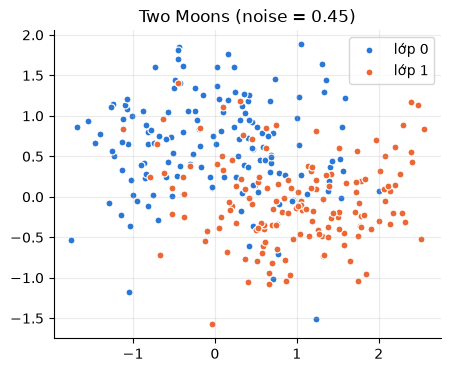

In [5]:
X_moons, y_moons = make_moons(n_samples=300, noise=0.45, random_state=3)

plt.figure(figsize=(5, 4))
for k in (0, 1):
    plt.scatter(*X_moons[y_moons == k].T, s=25, label=f"lớp {k}",
                edgecolor="white", linewidth=0.8)
plt.legend(); plt.title("Two Moons (noise = 0.45)"); plt.show()

In [6]:
# Chia train/test 70/30, giữ tỉ lệ lớp (stratify)
Xi_tr, Xi_te, yi_tr, yi_te = train_test_split(X_iris.to_numpy(), y_iris, test_size=0.3,
                                              random_state=SEED, stratify=y_iris)
Xm_tr, Xm_te, ym_tr, ym_te = train_test_split(X_moons, y_moons, test_size=0.3,
                                              random_state=SEED, stratify=y_moons)
print("Iris :", Xi_tr.shape, Xi_te.shape)
print("Moons:", Xm_tr.shape, Xm_te.shape)

Iris : (105, 4) (45, 4)
Moons: (210, 2) (90, 2)


## A2. Sử dụng các thuật toán bằng sklearn

Mọi mô hình sklearn dùng chung một API: `model.fit(X_train, y_train)`, `model.predict(X_test)`, `model.score(X_test, y_test)`.

| Thuật toán | Ý tưởng chính | Tham số quan trọng |
|---|---|---|
| **Bagging** | Nhiều cây sâu, mỗi cây học trên một mẫu bootstrap; bỏ phiếu đa số. Giảm **phương sai**. | `estimator`, `n_estimators`, `max_samples` |
| **Random Forest** | Bagging, thêm: mỗi lần tách nút chỉ xét ngẫu nhiên một tập con đặc trưng, nên các cây ít tương quan hơn. | `n_estimators`, `max_features`, `max_depth` |
| **AdaBoost** | Học tuần tự các mô hình yếu (thường là stump); tăng trọng số các mẫu bị phân loại sai. Giảm **độ chệch**. | `estimator`, `n_estimators`, `learning_rate` |
| **Gradient Boosting** | Mỗi cây mới khớp với gradient âm (phần dư) của hàm mất mát hiện tại. | `n_estimators`, `learning_rate`, `max_depth` |
| **XGBoost** | Gradient Boosting tối ưu: xấp xỉ bậc hai, chính quy hóa L1/L2, chạy song song. | `n_estimators`, `learning_rate`, `max_depth`, `reg_lambda` |

Các **mô hình simple** để so sánh: Decision Tree, Logistic Regression, KNN, SVM.

In [7]:
def quick_check(name):
    # Huấn luyện bản sao của models[name] trên Iris và in accuracy test
    m = clone(models[name]).fit(Xi_tr, yi_tr)
    print(f"{name:<20} accuracy Iris test = {m.score(Xi_te, yi_te):.3f}")
    return m

# Mô hình đơn (LR, KNN, SVM nhạy với thang đo nên chuẩn hóa trước)
models = {
    "Decision Tree":       DecisionTreeClassifier(random_state=SEED),
    "Logistic Regression": make_pipeline(StandardScaler(), LogisticRegression(max_iter=2000)),
    "SVM (RBF)":           make_pipeline(StandardScaler(), SVC(kernel="rbf")),
}
for name in models:
    quick_check(name)

Decision Tree        accuracy Iris test = 0.933
Logistic Regression  accuracy Iris test = 0.911
SVM (RBF)            accuracy Iris test = 0.933


**Bagging:** 100 cây quyết định sâu (không cắt ).

In [8]:
models["Bagging"] = BaggingClassifier(estimator=DecisionTreeClassifier(),
                                      n_estimators=100, random_state=SEED)
quick_check("Bagging");

Bagging              accuracy Iris test = 0.933


**Random Forest:** `max_features="sqrt"` nghĩa là mỗi nút chỉ xét √d đặc trưng ngẫu nhiên. Thuộc tính `feature_importances_` cho biết đặc trưng nào hữu ích nhất.

In [9]:
models["Random Forest"] = RandomForestClassifier(n_estimators=100, max_features="sqrt",
                                                 random_state=SEED)
rf = quick_check("Random Forest")
pd.Series(rf.feature_importances_, index=X_iris.columns).sort_values(ascending=False).round(3)

Random Forest        accuracy Iris test = 0.889


petal width     0.455
petal length    0.400
sepal length    0.121
sepal width     0.024
dtype: float64

**AdaBoost:** mô hình yếu là stump (`max_depth=1`). `learning_rate` nhỏ thì mỗi vòng đóng góp ít hơn, cần nhiều vòng hơn nhưng ít overfit hơn.

In [10]:
models["AdaBoost"] = AdaBoostClassifier(estimator=DecisionTreeClassifier(max_depth=1),
                                        n_estimators=100, learning_rate=0.5,
                                        random_state=SEED)
quick_check("AdaBoost");

AdaBoost             accuracy Iris test = 0.933


**Gradient Boosting:** các cây nông (`max_depth=3`) được cộng dồn, mỗi cây nhân với `learning_rate`.

In [11]:
models["Gradient Boosting"] = GradientBoostingClassifier(n_estimators=100, learning_rate=0.1,
                                                         max_depth=3, random_state=SEED)
quick_check("Gradient Boosting");

Gradient Boosting    accuracy Iris test = 0.933


**XGBoost:** API giống sklearn. Lưu ý nhãn phải là số nguyên 0 đến K−1 (đã mã hóa bằng `LabelEncoder` ở A1).

In [12]:
models["XGBoost"] = XGBClassifier(n_estimators=100, learning_rate=0.1, max_depth=3,
                                  random_state=SEED)
quick_check("XGBoost");

XGBoost              accuracy Iris test = 0.933


### Decision boundary trên Two Moons

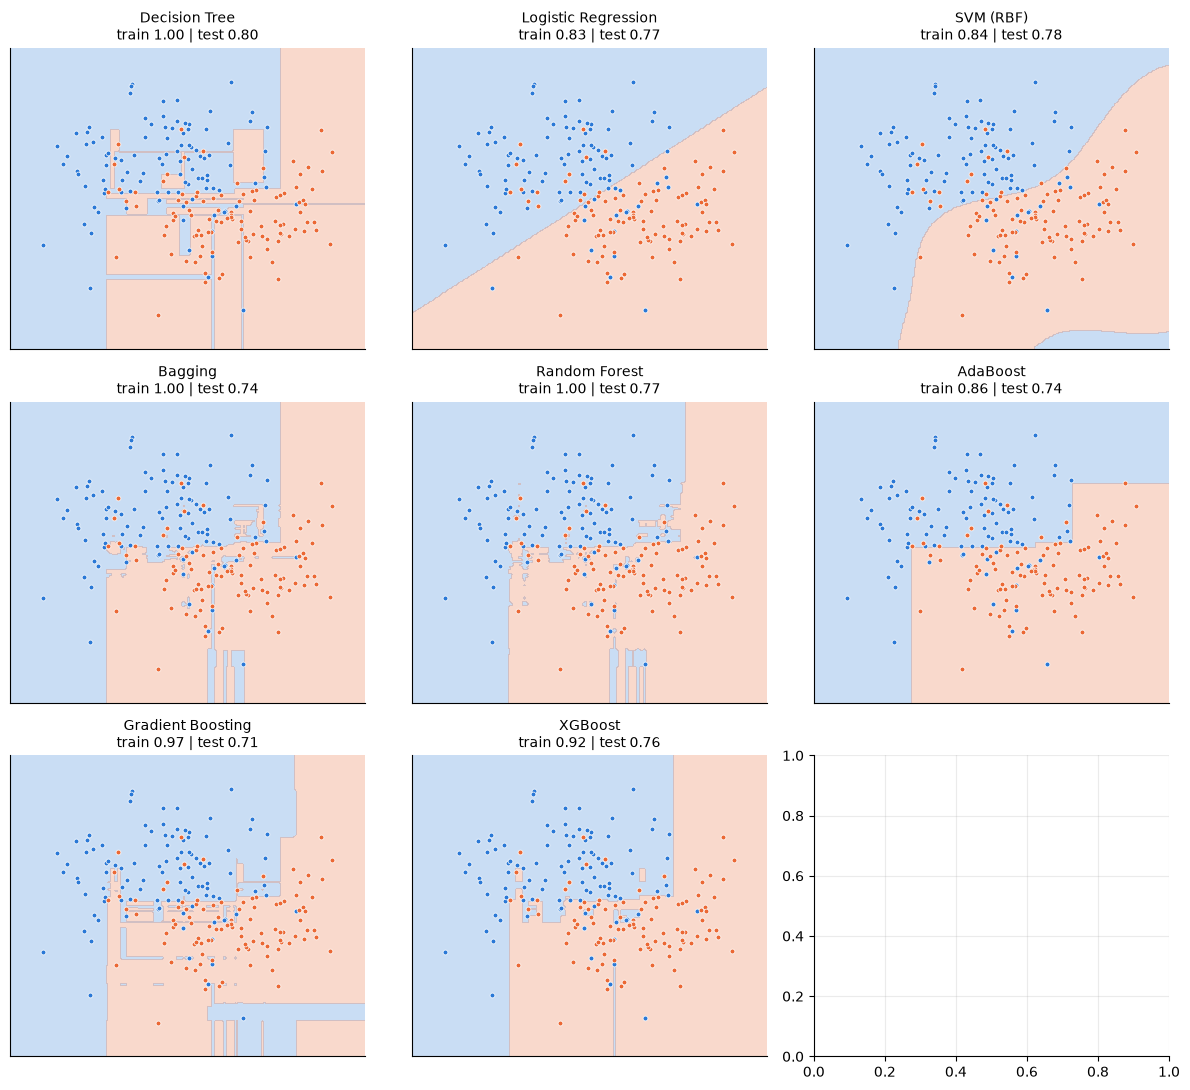

In [13]:
def plot_boundaries(models, X_tr, y_tr, X_te, y_te):
    xx, yy = np.meshgrid(np.linspace(X_tr[:, 0].min() - .5, X_tr[:, 0].max() + .5, 250),
                         np.linspace(X_tr[:, 1].min() - .5, X_tr[:, 1].max() + .5, 250))
    grid = np.c_[xx.ravel(), yy.ravel()]
    fig, axes = plt.subplots(3, 3, figsize=(12, 11))
    for ax, (name, model) in zip(axes.ravel(), models.items()):
        m = clone(model).fit(X_tr, y_tr)
        zz = m.predict(grid).reshape(xx.shape)
        ax.contourf(xx, yy, zz, levels=[-.5, .5, 1.5], colors=COLORS[:2], alpha=0.25)
        for k in (0, 1):
            ax.scatter(*X_tr[y_tr == k].T, s=12, color=COLORS[k], edgecolor="white", linewidth=0.5)
        ax.set_title(f"{name}\ntrain {m.score(X_tr, y_tr):.2f} | test {m.score(X_te, y_te):.2f}",
                     fontsize=10)
        ax.set_xticks([]); ax.set_yticks([]); ax.grid(False)
    plt.tight_layout(); plt.show()

plot_boundaries(models, Xm_tr, ym_tr, Xm_te, ym_te)

**Nhận xét:** Cây đơn đạt train 1.00 với biên quyết định vụn vặt bám theo từng điểm nhiễu: overfit, variance cao. Bagging và Random Forest lấy phiếu của nhiều cây nên biên đỡ vụn hơn, nhưng vẫn còn vùng nhỏ lẻ vì từng cây đều sâu. AdaBoost cộng các stump nên biên gồm các đoạn song song trục và ít overfit hơn (train 0.86). Tập test chỉ có 90 điểm, mỗi điểm bằng 1.1% accuracy, nên không kết luận từ một lần chia mà xem cột CV ở A3.

## A3. Bảng benchmark

Hàm `benchmark` huấn luyện từng mô hình và ghi lại: Accuracy, Macro F1 trên tập test, accuracy CV 5 fold trên tập train (mean, std), thời gian train và predict. Phần B dùng lại hàm này.

In [14]:
ENSEMBLE_TYPES = (BaggingClassifier, RandomForestClassifier, AdaBoostClassifier,
                  GradientBoostingClassifier, XGBClassifier)

def benchmark(models, X_tr, X_te, y_tr, y_te, cv=5):
    rows = []
    for name, model in models.items():
        m = clone(model)
        t0 = time.perf_counter(); m.fit(X_tr, y_tr); t_fit = time.perf_counter() - t0
        t0 = time.perf_counter(); y_pred = m.predict(X_te); t_pred = time.perf_counter() - t0
        row = {"Mô hình": name,
               "Loại": "Ensemble" if isinstance(model, ENSEMBLE_TYPES) else "Đơn",
               "Accuracy": accuracy_score(y_te, y_pred),
               "Macro F1": f1_score(y_te, y_pred, average="macro"),
               "Train (s)": t_fit, "Predict (s)": t_pred}
        if cv:
            s = cross_val_score(clone(model), X_tr, y_tr, cv=cv)
            row["CV mean"], row["CV std"] = s.mean(), s.std()
        rows.append(row)
    df = pd.DataFrame(rows).set_index("Mô hình")
    sort_by = "CV mean" if cv else "Accuracy"
    return df.sort_values(sort_by, ascending=False).round(4)

res_iris = benchmark(models, Xi_tr, Xi_te, yi_tr, yi_te)
res_moons = benchmark(models, Xm_tr, Xm_te, ym_tr, ym_te)
print("IRIS"); display(res_iris)
print("TWO MOONS"); display(res_moons)

IRIS


,Loại,Accuracy,Macro F1,Train (s),Predict (s),CV mean,CV std
Mô hình,,,,,,,
Logistic Regression,Đơn,0.9111,0.9107,0.0085,0.0006,0.9810,0.0233
SVM (RBF),Đơn,0.9333,0.9333,0.0038,0.0010,0.9714,0.0233
Bagging,Ensemble,0.9333,0.9333,0.1980,0.0112,0.9524,0.0301
Random Forest,Ensemble,0.8889,0.8878,0.1627,0.0104,0.9524,0.0301
Gradient Boosting,Ensemble,0.9333,0.9333,0.2285,0.0015,0.9524,0.0301
AdaBoost,Ensemble,0.9333,0.9333,0.1774,0.0125,0.9524,0.0301
XGBoost,Ensemble,0.9333,0.9333,0.1908,0.0020,0.9524,0.0426
Decision Tree,Đơn,0.9333,0.9327,0.0019,0.0003,0.9429,0.0190


TWO MOONS


,Loại,Accuracy,Macro F1,Train (s),Predict (s),CV mean,CV std
Mô hình,,,,,,,
Logistic Regression,Đơn,0.7667,0.7659,0.0036,0.0005,0.8381,0.0551
SVM (RBF),Đơn,0.7778,0.7773,0.0027,0.0011,0.8286,0.0410
AdaBoost,Ensemble,0.7444,0.7442,0.1629,0.0129,0.8095,0.0499
Random Forest,Ensemble,0.7667,0.7659,0.1377,0.0083,0.7952,0.0323
XGBoost,Ensemble,0.7556,0.7545,0.1464,0.0021,0.7905,0.0530
Gradient Boosting,Ensemble,0.7111,0.7105,0.0953,0.0008,0.7619,0.0543
Bagging,Ensemble,0.7444,0.7429,0.2053,0.0128,0.7619,0.0452
Decision Tree,Đơn,0.8000,0.7996,0.0018,0.0003,0.7333,0.0350


### Ảnh hưởng của  `n_estimators` (Two Moons, CV 5 fold)

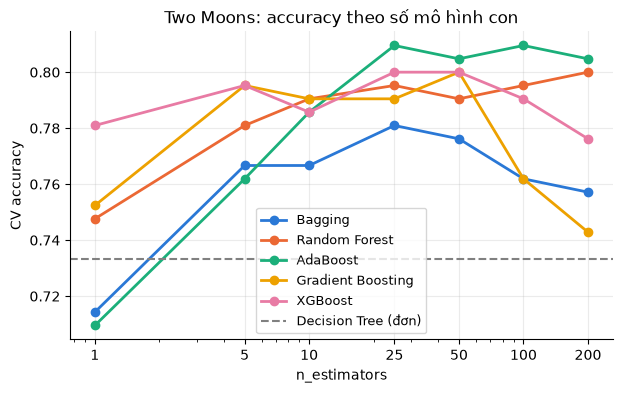

In [15]:
n_list = [1, 5, 10, 25, 50, 100, 200]
ens_names = ["Bagging", "Random Forest", "AdaBoost", "Gradient Boosting", "XGBoost"]
dt_cv = cross_val_score(clone(models["Decision Tree"]), Xm_tr, ym_tr, cv=5).mean()

plt.figure(figsize=(7, 4))
for name in ens_names:
    scores = [cross_val_score(clone(models[name]).set_params(n_estimators=n),
                              Xm_tr, ym_tr, cv=5).mean() for n in n_list]
    plt.plot(n_list, scores, marker="o", linewidth=2, markersize=6, label=name)
plt.axhline(dt_cv, color="gray", linestyle="--", linewidth=1.5, label="Decision Tree (đơn)")
plt.xscale("log"); plt.xticks(n_list, n_list)
plt.xlabel("n_estimators"); plt.ylabel("CV accuracy")
plt.title("Two Moons: accuracy theo số mô hình con")
plt.legend(fontsize=9); plt.show()

**Nhận xét:**
- Theo CV, mọi ensemble đều hơn Decision Tree đơn trên cả hai tập (Two Moons: từ 0.733 lên 0.76 đến 0.81; Iris: từ 0.943 lên 0.952).
- Logistic Regression và SVM vẫn đứng đầu: Iris gần như tách được bằng biên tuyến tính, còn Two Moons rất nhiễu nên mô hình có biên mượt có lợi. Ensemble chủ yếu cải thiện mô hình nền là cây, không phải lúc nào cũng thắng mọi mô hình đơn.
- Cột Accuracy test dao động mạnh vì tập test nhỏ (45 và 90 mẫu), nên bảng sắp xếp theo CV mean.
- Hình `n_estimators`: Bagging và Random Forest tăng nhanh ở vài cây đầu rồi dao động trong biên độ nhiễu của CV (về lý thuyết thêm cây không gây overfit). Gradient Boosting và XGBoost giảm khi số vòng quá lớn vì boosting tiếp tục khớp nhiễu, nên cần chọn `n_estimators` bằng validation hoặc early stopping.

---
# Phần B. Bài tập: nhận dạng chữ số viết tay (Optdigits)

### Dữ liệu: *Optical Recognition of Handwritten Digits* (UCI id 80)
- **5620 ảnh** chữ số 0 đến 9 do 43 người viết, **10 lớp** .
- Ảnh gốc 32×32 nhị phân được chia thành các khối 4×4 không chồng nhau; mỗi đặc trưng là **số pixel đen trong một khối**. Kết quả là ảnh **8×8 = 64 đặc trưng**, giá trị nguyên 0 đến 16.
- Cùng bài toán với MNIST nhưng nhỏ hơn (64 so với 784 đặc trưng) .
- `sklearn.datasets.load_digits` chỉ là tập test (1797 mẫu) của bộ này; bài này dùng đủ 5620 mẫu.

**Nộp bài:** notebook đã chạy hết các ô, đặt tên `MSSV_HoTen_Tuan5.ipynb`. Mỗi hình cần 1 đến 3 câu nhận xét.

In [16]:
# B0. Tải và chia dữ liệu (đã cho sẵn, không sửa)
digits = fetch_ucirepo(id=80)
X_d = digits.data.features.to_numpy()
y_d = digits.data.targets.to_numpy().ravel()
Xd_tr, Xd_te, yd_tr, yd_te = train_test_split(X_d, y_d, test_size=0.3,
                                              random_state=SEED, stratify=y_d)
print("Toàn bộ:", X_d.shape, "| Train:", Xd_tr.shape, "| Test:", Xd_te.shape)

Toàn bộ: (5620, 64) | Train: (3934, 64) | Test: (1686, 64)


## B1. EDA
1. In kích thước dữ liệu, số giá trị thiếu, giá trị nhỏ nhất và lớn nhất của đặc trưng.
2. Vẽ biểu đồ cột số mẫu mỗi lớp. Dữ liệu có cân bằng không?
3. Hiển thị 1 ảnh mẫu cho mỗi chữ số (gợi ý: `X_d[i].reshape(8, 8)`, `plt.imshow(..., cmap="gray_r")`).
4. Hiển thị ảnh trung bình của mỗi lớp. Cặp chữ số nào trông giống nhau nhất?
5. Đếm số đặc trưng có phương sai bằng 0 và chỉ ra vị trí của chúng trên lưới 8×8. Vì sao chúng không giúp ích cho mô hình?

In [ ]:
# TODO B1.1 và B1.2


In [18]:
# TODO B1.3 và B1.4

In [19]:
# TODO B1.5

**Nhận xét B1:** _(viết ở đây)_

## B2. Huấn luyện các mô hình
1. Tạo dict `models_d` gồm **4 mô hình đơn và các mô hình ensemble** như Phần A (có thể dùng `clone(models["..."])`). Gợi ý cấu hình: Bagging, Random Forest 100 cây; Gradient Boosting 100 cây; XGBoost 200 cây, `max_depth=4`.
2. AdaBoost: tạo **hai** phiên bản, mô hình yếu `max_depth=1` (stump) và `max_depth=3`, cùng 200 vòng.

In [20]:
# TODO B2
models_d = {
    # "Decision Tree": ...,
}

## B3. Benchmark
1. Dùng hàm `benchmark` của Phần A với `cv=None` (bỏ CV để tiết kiệm thời gian) để lập bảng so sánh.
2. Vẽ confusion matrix của **mô hình ensemble tốt nhất** (gợi ý: `ConfusionMatrixDisplay.from_predictions`). Cặp chữ số nào bị nhầm nhiều nhất?
3. Hiển thị `feature_importances_` của Random Forest dưới dạng ảnh 8×8. So sánh với kết quả B1.5.

In [21]:
# TODO B3.1

In [22]:
# TODO B3.2

In [23]:
# TODO B3.3

## B4. Câu hỏi thảo luận (trả lời ngắn, dựa trên bảng của bạn)
1. Ensemble tốt nhất hơn Decision Tree bao nhiêu điểm phần trăm accuracy? Giải thích .
2. Có mô hình simple nào ngang hoặc hơn các ensemble không? Vì sao
3. AdaBoost với stump so với `max_depth=3`: kết quả khác nhau thế nào, vì sao? (Gợi ý: bài toán có 10 lớp.)
4. Nếu cần dự đoán nhanh trên thiết bị yếu, bạn chọn mô hình nào? Dựa vào cột thời gian và accuracy.

**Trả lời:**
1. ...
2. ...
3. ...
4. ...